In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay
df=pd.read_csv("student_productivity_final.csv")
df

,student_id,age,gender,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,stress_level,focus_score,final_grade,productivity_score
0,1,23,Female,4.35,3.63,3.38,2.73,1.83,5.26,6,347,111.0,10.0,57.0,81.87,33.78
1,2,20,Male,6.14,6.58,5.48,1.51,3.13,1.73,13,403,28.0,10.0,49.0,60.90,48.99
2,3,29,Female,4.98,3.26,4.83,3.63,0.18,4.71,1,419,102.0,2.0,38.0,86.22,36.60
3,4,27,Female,3.19,4.58,10.06,3.95,5.75,2.52,9,178,28.0,6.0,50.0,71.77,19.87
4,5,24,Male,7.67,6.21,3.02,1.59,5.46,5.65,8,436,105.0,6.0,41.0,90.13,52.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20095,19154,19,Male,9.59,5.35,5.83,0.43,2.14,5.17,10,462,11.0,2.0,77.0,46.06,75.04
20096,1890,25,Male,3.41,4.55,1.02,5.32,5.31,0.45,14,324,101.0,3.0,70.0,59.08,52.04
20097,1686,23,Female,1.65,4.72,5.91,3.70,5.48,0.60,1,228,43.0,8.0,40.0,78.19,16.03
20098,14384,23,Male,3.27,7.03,8.67,7.63,1.12,2.29,10,168,98.0,6.0,71.0,82.37,39.60


In [6]:
df.shape

(20100, 16)

In [7]:
df.columns

Index(['student_id', 'age', 'gender', 'study_hours_per_day', 'sleep_hours',
       'phone_usage_hours', 'social_media_hours', 'youtube_hours',
       'gaming_hours', 'breaks_per_day', 'coffee_intake_mg',
       'exercise_minutes', 'stress_level', 'focus_score', 'final_grade',
       'productivity_score'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20100 entries, 0 to 20099
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           20100 non-null  int64  
 1   age                  20100 non-null  int64  
 2   gender               20100 non-null  str    
 3   study_hours_per_day  20088 non-null  float64
 4   sleep_hours          20088 non-null  float64
 5   phone_usage_hours    20088 non-null  float64
 6   social_media_hours   20088 non-null  float64
 7   youtube_hours        20100 non-null  float64
 8   gaming_hours         20100 non-null  float64
 9   breaks_per_day       20100 non-null  int64  
 10  coffee_intake_mg     20100 non-null  int64  
 11  exercise_minutes     20084 non-null  float64
 12  stress_level         20088 non-null  float64
 13  focus_score          20088 non-null  float64
 14  final_grade          20100 non-null  float64
 15  productivity_score   20100 non-null  float64
dt

In [9]:
df.isna().sum()

student_id              0
age                     0
gender                  0
study_hours_per_day    12
sleep_hours            12
phone_usage_hours      12
social_media_hours     12
youtube_hours           0
gaming_hours            0
breaks_per_day          0
coffee_intake_mg        0
exercise_minutes       16
stress_level           12
focus_score            12
final_grade             0
productivity_score      0
dtype: int64

In [10]:
df.describe()

,student_id,age,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,stress_level,focus_score,final_grade,productivity_score
count,20100.000000,20100.000000,20088.000000,20088.000000,20088.000000,20088.000000,20100.000000,20100.000000,20100.000000,20100.000000,20084.000000,20088.000000,20088.000000,20100.000000,20100.000000
mean,9998.191741,23.008955,5.254375,6.516415,6.248106,4.004575,2.989822,2.988559,7.543632,249.753532,59.619249,5.477300,64.446237,70.272870,50.178059
std,5771.846588,3.752574,2.742370,2.029547,3.314044,2.305751,1.729558,1.732873,4.015696,143.630119,34.614084,2.866051,20.174874,17.282819,16.088000
min,1.000000,17.000000,0.500000,3.000000,0.500000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,30.000000,40.000000,0.000000
25%,5002.750000,20.000000,2.900000,4.770000,3.370000,2.000000,1.490000,1.490000,4.000000,126.000000,30.000000,3.000000,47.000000,55.460000,38.690000
50%,9993.500000,23.000000,5.250000,6.500000,6.235000,4.010000,2.980000,2.970000,8.000000,249.000000,60.000000,5.000000,65.000000,70.315000,50.230000
75%,14995.250000,26.000000,7.640000,8.302500,9.100000,5.970000,4.480000,4.500000,11.000000,373.000000,90.000000,8.000000,82.000000,85.350000,61.780000
max,20000.000000,29.000000,10.000000,10.000000,12.000000,8.000000,6.000000,6.000000,14.000000,499.000000,119.000000,10.000000,99.000000,99.990000,100.000000


In [11]:
df["study_hours_per_day"] = df["study_hours_per_day"].fillna(df["study_hours_per_day"].median())
df["sleep_hours"] = df["sleep_hours"].fillna(df["sleep_hours"].median())
df["phone_usage_hours"] = df["phone_usage_hours"].fillna(df["phone_usage_hours"].median())
df["social_media_hours"] = df["social_media_hours"].fillna(df["social_media_hours"].median())
df["exercise_minutes"] = df["exercise_minutes"].fillna(df["exercise_minutes"].median())
df["stress_level"] = df["stress_level"].fillna(df["stress_level"].median())
df["focus_score"] = df["focus_score"].fillna(df["focus_score"].median())
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

In [12]:
df.isna().sum()

student_id             0
age                    0
gender                 0
study_hours_per_day    0
sleep_hours            0
phone_usage_hours      0
social_media_hours     0
youtube_hours          0
gaming_hours           0
breaks_per_day         0
coffee_intake_mg       0
exercise_minutes       0
stress_level           0
focus_score            0
final_grade            0
productivity_score     0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(100)

In [14]:
df = df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["gender"] = le.fit_transform(df["gender"])

In [17]:
df["total_screen_time_hours"] = (
    df["phone_usage_hours"] +
    df["youtube_hours"] +
    df["gaming_hours"] +
    df["social_media_hours"]
  )


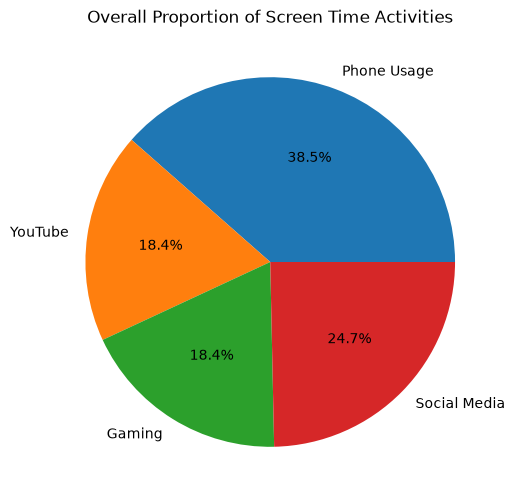

In [18]:
# Simple screen time pie chart
totals = [df["phone_usage_hours"].sum(), df["youtube_hours"].sum(), df["gaming_hours"].sum(), df["social_media_hours"].sum()]
labels = ["Phone Usage", "YouTube", "Gaming", "Social Media"]

plt.figure(figsize=(6, 6))
plt.pie(totals, labels=labels, autopct="%1.1f%%")
plt.title("Overall Proportion of Screen Time Activities")
plt.show()

In [19]:
df = df.drop(columns=[
    "phone_usage_hours",
    "youtube_hours",
    "gaming_hours",
    "social_media_hours"
])

In [20]:
df.corr() ['productivity_score']

student_id                 0.012579
age                       -0.005423
gender                     0.003703
study_hours_per_day        0.732624
sleep_hours                0.341029
breaks_per_day            -0.005836
coffee_intake_mg           0.010190
exercise_minutes           0.002831
stress_level              -0.196902
focus_score                0.411545
final_grade                0.001954
productivity_score         1.000000
total_screen_time_hours   -0.228107
Name: productivity_score, dtype: float64

In [21]:
df.drop(columns=["student_id",'age','gender','breaks_per_day','coffee_intake_mg','exercise_minutes','final_grade'],inplace=True)

C:\Users\JUVANS CJ\AppData\Local\Temp\ipykernel_22912\1821588022.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["student_id",'age','gender','breaks_per_day','coffee_intake_mg','exercise_minutes','final_grade'],inplace=True)


In [22]:
df

,study_hours_per_day,sleep_hours,stress_level,focus_score,productivity_score,total_screen_time_hours
0,4.35,3.63,10.0,57.0,33.78,13.20
1,6.14,6.58,10.0,49.0,48.99,11.85
2,4.98,3.26,2.0,38.0,36.60,13.35
3,3.19,4.58,6.0,50.0,19.87,22.28
4,7.67,6.21,6.0,41.0,52.90,15.72
...,...,...,...,...,...,...
19995,4.81,7.83,3.0,89.0,60.43,22.24
19996,0.83,4.49,10.0,56.0,17.84,14.88
19997,9.36,4.33,9.0,69.0,65.56,11.69
19998,0.74,4.44,5.0,53.0,28.06,17.26


In [23]:
df["productivity_category"] = pd.cut(
    df["productivity_score"],
    bins=[-float("inf"), 40, 70, float("inf")],
    labels=["Low", "Medium", "High"]
)


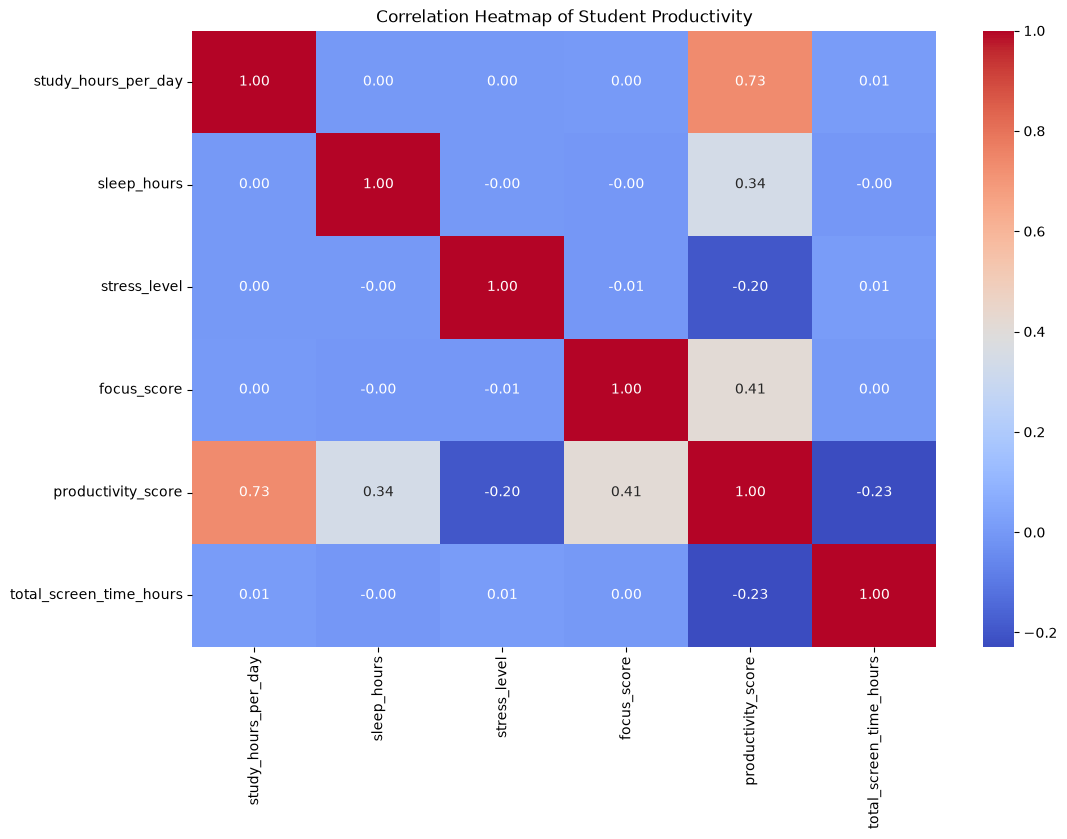

In [24]:
plt.figure(figsize=(12,8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Productivity")
plt.show()

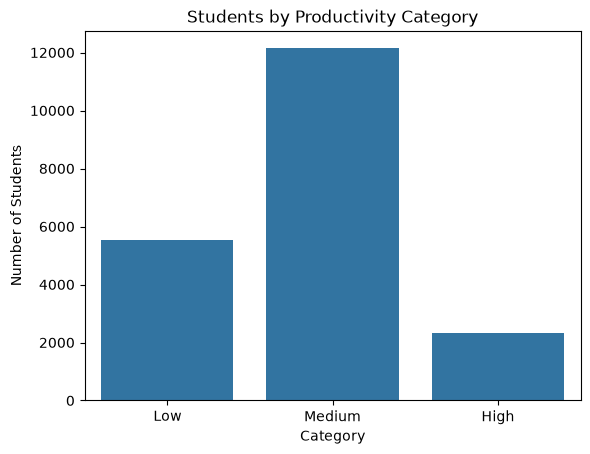

In [25]:
sns.countplot(data=df, x="productivity_category", order=["Low", "Medium", "High"])
plt.title("Students by Productivity Category")
plt.xlabel("Category")
plt.ylabel("Number of Students")
plt.show()

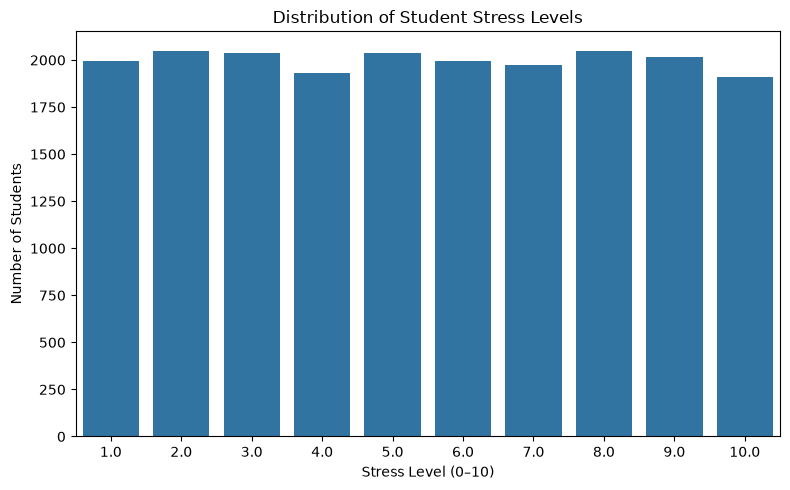

In [26]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="stress_level"
)

plt.title("Distribution of Student Stress Levels")
plt.xlabel("Stress Level (0–10)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


In [27]:
df.shape

(20000, 7)

In [28]:
x = df.drop(
    columns=["productivity_score","productivity_category"])
x

,study_hours_per_day,sleep_hours,stress_level,focus_score,total_screen_time_hours
0,4.35,3.63,10.0,57.0,13.20
1,6.14,6.58,10.0,49.0,11.85
2,4.98,3.26,2.0,38.0,13.35
3,3.19,4.58,6.0,50.0,22.28
4,7.67,6.21,6.0,41.0,15.72
...,...,...,...,...,...
19995,4.81,7.83,3.0,89.0,22.24
19996,0.83,4.49,10.0,56.0,14.88
19997,9.36,4.33,9.0,69.0,11.69
19998,0.74,4.44,5.0,53.0,17.26


In [29]:
y = df["productivity_category"]
y

0           Low
1        Medium
2           Low
3           Low
4        Medium
          ...  
19995    Medium
19996       Low
19997    Medium
19998       Low
19999       Low
Name: productivity_category, Length: 20000, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']

In [30]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,)


In [31]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [32]:
y.value_counts()

productivity_category
Medium    12139
Low        5540
High       2321
Name: count, dtype: int64

In [33]:
smote = SMOTE(random_state=42)
x_train, y_train = smote.fit_resample(x_train, y_train)

In [34]:
y_train.value_counts()

productivity_category
Low       9719
Medium    9719
High      9719
Name: count, dtype: int64

In [35]:
from sklearn.metrics import accuracy_score, classification_report

models = [
    RandomForestClassifier(),
    DecisionTreeClassifier(),
    KNeighborsClassifier(),
    GaussianNB()
]

for model in models:
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    print("\n", type(model).__name__)
    print("Accuracy:", accuracy_score(y_test, y_pred) * 100)
    print(classification_report(y_test, y_pred))


 RandomForestClassifier
Accuracy: 84.45
              precision    recall  f1-score   support

        High       0.72      0.79      0.75       484
         Low       0.81      0.87      0.84      1096
      Medium       0.89      0.84      0.87      2420

    accuracy                           0.84      4000
   macro avg       0.81      0.83      0.82      4000
weighted avg       0.85      0.84      0.85      4000


 DecisionTreeClassifier
Accuracy: 79.95
              precision    recall  f1-score   support

        High       0.66      0.73      0.69       484
         Low       0.76      0.81      0.78      1096
      Medium       0.85      0.81      0.83      2420

    accuracy                           0.80      4000
   macro avg       0.76      0.78      0.77      4000
weighted avg       0.80      0.80      0.80      4000


 KNeighborsClassifier
Accuracy: 80.22500000000001
              precision    recall  f1-score   support

        High       0.61      0.83      0.71       

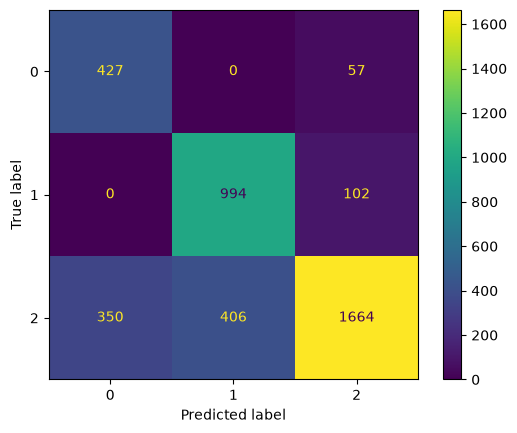

In [36]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [37]:
estimator = RandomForestClassifier(random_state=42)

param_distributions = {
    'n_estimators': [100, 150, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}


rf_search = RandomizedSearchCV(
    estimator=estimator,
    param_distributions=param_distributions,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=2
)


rf_search.fit(x_train, y_train)


best_model = rf_search.best_estimator_
y_pred = best_model.predict(x_test)


print("--- Search Results ---")
print("Best Parameters:", rf_search.best_params_)
print(f"Best CV Score: {rf_search.best_score_ * 100:.2f}%\n")

print("--- Full Classification Report ---")
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
--- Search Results ---
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 15}
Best CV Score: 92.13%

--- Full Classification Report ---
              precision    recall  f1-score   support

        High       0.73      0.78      0.75       484
         Low       0.81      0.88      0.84      1096
      Medium       0.90      0.85      0.87      2420

    accuracy                           0.85      4000
   macro avg       0.81      0.84      0.82      4000
weighted avg       0.85      0.85      0.85      4000



In [38]:
# joblib.dump(rf_best, "focusiqfinal.pkl")
# joblib.dump(scaler, "focusiq_scalerfinal.pkl")
print("Model and scaler saved successfully!")

Model and scaler saved successfully!
